In [18]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations_with_replacement

In [19]:
class PolynomialRegression:
    def __init__(self, learning_rate=0.01, max_iter=1000, standardize=True, degree=0, max_degree=5):
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.standardize = standardize
        self.degree = degree
        self.max_degree = max_degree

        self.weights = None
        self.bias = 0
        self.loss_history = []

        self.mean = None
        self.std = None

        self.best_degree = None
        self.n_features = None

    def _polynomial_features(self, X, degree):
        features = []

        for d in range(1, degree + 1):
            for indices in combinations_with_replacement(range(X.shape[1]), d):
                feature = np.prod(X[:, indices], axis=1)
                features.append(feature)

        return np.column_stack(features)

    def _lin_fit(self, X, y):
        if self.standardize:
            self.mean = X.mean(axis=0)
            self.std = X.std(axis=0)
            self.std[self.std == 0] = 1
            X = (X - self.mean) / self.std

        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history = []

        for _ in range(self.max_iter):
            y_pred = X @ self.weights + self.bias
            errors = y_pred - y
            loss = np.mean(errors ** 2)
            self.loss_history.append(loss)

            grad_w = (2 / n_samples) * (X.T @ errors)
            grad_b = (2 / n_samples) * np.sum(errors)

            self.weights -= self.learning_rate * grad_w
            self.bias -= self.learning_rate * grad_b

    def _find_best_degree(self, X, y):
        indices = np.random.default_rng(42).permutation(len(y))
        folds = np.array_split(indices, 5)

        best_degree = 1
        best_mse = float('inf')

        for degree in range(1, self.max_degree + 1):
            X_poly = self._polynomial_features(X, degree)
            errors = []

            for i in range(5):
                val_idx = folds[i]
                train_idx = np.concatenate([folds[j] for j in range(5) if j != i])

                self._lin_fit(X_poly[train_idx], y[train_idx])

                X_val = X_poly[val_idx]
                if self.standardize:
                    X_val = (X_val - self.mean) / self.std

                y_pred = X_val @ self.weights + self.bias
                errors.append(self.mse(y_pred, y[val_idx]))

            avg_mse = np.mean(errors)

            if avg_mse < best_mse:
                best_mse = avg_mse
                best_degree = degree

        return best_degree

    def fit(self, X, y):
        self.n_features = X.shape[1]
        if self.degree == 0:
            self.best_degree = self._find_best_degree(X, y)
        else:
            self.best_degree = self.degree

        X_poly = self._polynomial_features(X, self.best_degree)
        self._lin_fit(X_poly, y)

    def predict(self, X):
        X_poly = self._polynomial_features(X, self.best_degree)

        if self.standardize:
            X_poly = (X_poly - self.mean) / self.std

        return X_poly @ self.weights + self.bias

    def _feature_combinations(self):
        combinations = []

        for d in range(1, self.best_degree + 1):
            for indices in combinations_with_replacement(range(self.n_features), d):
                combinations.append(indices)

        return combinations

    @staticmethod
    def mse(y_pred, y_true):
        return np.mean((y_pred - y_true)**2)

    @staticmethod
    def mae(y_pred, y_true):
        return np.mean(np.abs(y_pred - y_true))

    @staticmethod
    def rmse(y_pred, y_true):
        return np.sqrt(np.mean((y_pred - y_true)**2))

    @staticmethod
    def r2(y_pred, y_true):
        return 1 - ((y_pred - y_true)**2).sum() / ((np.mean(y_true) - y_true)**2).sum()

**Проверим наш класс на сгенерированных данных:**

$y = 3x^2 + 2x + 5 + \varepsilon$

Оптимальная степень: 2
MSE: 876.4090
R2: 0.9004


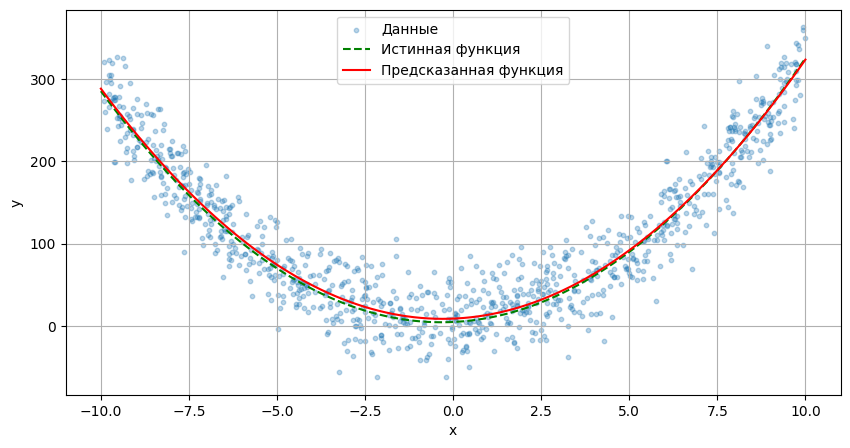

In [20]:
np.random.seed(42)

X = np.random.uniform(-10, 10, 1000).reshape(-1, 1)
y = 3 * X.ravel()**2 + 2 * X.ravel() + 5 + np.random.normal(0, 30, 1000)

model = PolynomialRegression(learning_rate=0.05, max_iter=1000, standardize=True, degree=0)
model.fit(X, y)

print(f"Оптимальная степень: {model.best_degree}")
print(f"MSE: {model.mse(model.predict(X), y):.4f}")
print(f"R2: {model.r2(model.predict(X), y):.4f}")

X_line = np.linspace(-10, 10, 100).reshape(-1, 1)
y_pred = model.predict(X_line)
y_true = 3 * X_line.ravel()**2 + 2 * X_line.ravel() + 5

plt.figure(figsize=(10, 5))

plt.scatter(X, y, s=10, alpha=0.3, label='Данные')
plt.plot(X_line, y_true, 'g--', label='Истинная функция')
plt.plot(X_line, y_pred, 'r', label='Предсказанная функция')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid()
plt.show()

In [22]:
combinations = model._feature_combinations()

weights = model.weights / model.std
bias = model.bias - np.sum(weights * model.mean)

for indices, weight in zip(combinations, weights):
    print(indices, weight)

print("bias:", bias)

(0,) 1.762198447618561
(0, 0) 2.965548136185862
bias: 9.09677379732446
